# Plot differentially accessible regions

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.pyplot import rcParams
from adjustText import adjust_text

import project_style_py as scp
scp.load_project_palettes('/lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_palettes.yaml'
)
scp.load_project_themes(
    '/lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_themes_py.yaml'
)

%config InlineBackend.figure_format = 'retina'

Successfully loaded palettes from: /software/conda/users/od5/bin2cell/lib/python3.8/site-packages/project_style_py/resources/palettes.yaml
Successfully loaded themes from: /software/conda/users/od5/bin2cell/lib/python3.8/site-packages/project_style_py/resources/themes.yaml
Successfully loaded palettes from: /lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_palettes.yaml
Successfully loaded themes from: /lustre/scratch124/humgen/projects_v2/cardinal_analysis/analysis/od5/annotation/freeze3_stats/freeze3_themes_py.yaml
Loading fonts for theme: default
Font saved to temporary file: /tmp/tmpmmakdjy1.ttf
Font saved to temporary file: /tmp/tmph7g0jrmd.ttf
Font saved to temporary file: /tmp/tmpq248wsjj.ttf
Font saved to temporary file: /tmp/tmpxi_lqdmy.ttf
Loading fonts for theme: theme_bw
Font saved to temporary file: /tmp/tmpp9im82fy.ttf
Font saved to temporary file: /tmp/tmpnpl8q53y.ttf
Font saved to temporary file: /tmp/tmpodfy0hd9.ttf
F

In [7]:
# Set Helvetica as default font (fallback to Arial / sans-serif if not installed)

import matplotlib as mpl

mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
mpl.rcParams["pdf.fonttype"] = 42   # editable text in Illustrator
mpl.rcParams["ps.fonttype"] = 42

In [8]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'

p_output = work_dir + 'DARs_archr/'

In [9]:
dars = pd.read_csv(p_output + 'archr_DARs_perturbation_df_pos_neg.txt', sep='\t')

In [10]:
dars

,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak
0,chr5,160293835,160294335,2.510966,0.268985,0.314875,CEBPD,chr5:160293835-160294335
1,chr1,904474,904974,-0.607930,0.896818,-0.068741,CEBPD,chr1:904474-904974
2,chr1,924624,925124,1.408424,0.896818,0.056715,CEBPD,chr1:924624-925124
3,chr1,1164796,1165296,-1.349496,0.896818,-0.081546,CEBPD,chr1:1164796-1165296
4,chr1,1782293,1782793,-0.921950,0.896818,-0.047462,CEBPD,chr1:1782293-1782793
...,...,...,...,...,...,...,...,...
734881,chrX,154378799,154379299,-0.201073,1.000000,-0.077259,TCF7,chrX:154378799-154379299
734882,chrX,154490474,154490974,0.032837,1.000000,0.006345,TCF7,chrX:154490474-154490974
734883,chrX,154527124,154527624,-0.686350,1.000000,-0.046747,TCF7,chrX:154527124-154527624
734884,chrX,154725290,154725790,1.300997,1.000000,0.018772,TCF7,chrX:154725290-154725790


In [11]:
grn_comb_high_conf = pd.read_csv((work_dir + 'eregulon_metadata_full_20runs_combined_min5recall.csv'), index_col=0)

In [12]:
grn_comb_high_conf

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full
ARID3A#chr11:107916525-107917025#RAB39A,ARID3A#chr11:107916525-107917025#RAB39A,ARID3A,chr11:107916525-107917025,RAB39A,-,+,ARID3A#chr11:107916525-107917025,chr11:107916525-107917025#RAB39A,ARID3A#RAB39A,6,6,6,6,12
ARID3A#chr11:64356450-64356950#GPR137,ARID3A#chr11:64356450-64356950#GPR137,ARID3A,chr11:64356450-64356950,GPR137,+,+,ARID3A#chr11:64356450-64356950,chr11:64356450-64356950#GPR137,ARID3A#GPR137,7,9,7,7,12
ARID3A#chr12:2691652-2692152#ITFG2,ARID3A#chr12:2691652-2692152#ITFG2,ARID3A,chr12:2691652-2692152,ITFG2,-,+,ARID3A#chr12:2691652-2692152,chr12:2691652-2692152#ITFG2,ARID3A#ITFG2,5,9,6,5,12
ARID3A#chr12:2944628-2945128#ITFG2,ARID3A#chr12:2944628-2945128#ITFG2,ARID3A,chr12:2944628-2945128,ITFG2,-,+,ARID3A#chr12:2944628-2945128,chr12:2944628-2945128#ITFG2,ARID3A#ITFG2,6,6,6,6,12
ARID3A#chr12:57456037-57456537#INHBE,ARID3A#chr12:57456037-57456537#INHBE,ARID3A,chr12:57456037-57456537,INHBE,+,+,ARID3A#chr12:57456037-57456537,chr12:57456037-57456537#INHBE,ARID3A#INHBE,5,5,7,5,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10,chrX:48958188-48958688,TFE3,+,+,ZSCAN10#chrX:48958188-48958688,chrX:48958188-48958688#TFE3,ZSCAN10#TFE3,9,11,9,10,19
ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10,chrX:49002006-49002506,TFE3,+,+,ZSCAN10#chrX:49002006-49002506,chrX:49002006-49002506#TFE3,ZSCAN10#TFE3,7,8,9,7,19
ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10,chrX:49073807-49074307,TFE3,+,+,ZSCAN10#chrX:49073807-49074307,chrX:49073807-49074307#TFE3,ZSCAN10#TFE3,7,7,9,7,19
ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10,chrX:49101053-49101553,TFE3,+,+,ZSCAN10#chrX:49101053-49101553,chrX:49101053-49101553#TFE3,ZSCAN10#TFE3,5,5,9,5,19


In [13]:
degs = pd.read_csv('/nfs/casm/team215mg/users/od5/projects/celltherapy/ipsc/multiome/tf_pilot/002_integrate_and_annotate/batch1_ipsc/ipsc_multiome_tf_degs_wilcoxon.csv')

In [14]:
degs

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,CEBPA,RIPK2,3.452059,2.778124,5.563262e-04,1.000000
1,CEBPA,SORT1,3.221702,1.944393,1.274315e-03,1.000000
2,CEBPA,CEP120,3.173986,2.290511,1.503612e-03,1.000000
3,CEBPA,TCAF1,3.050580,2.075775,2.283997e-03,1.000000
4,CEBPA,MTAP,3.007800,1.365392,2.631465e-03,1.000000
...,...,...,...,...,...,...
329404,TCF7,AK4,-4.660088,-0.314827,3.160741e-06,0.007900
329405,TCF7,COL23A1,-4.744262,-0.424571,2.092683e-06,0.006383
329406,TCF7,PVT1,-5.001014,-0.207392,5.702960e-07,0.002609
329407,TCF7,ADCY2,-5.697069,-0.324021,1.218845e-08,0.000064


In [15]:
# Merges DAR peaks with high-confidence GRN triplets by genomic region.
# Keeps all DAR rows that have matching GRN regions.

dar_grn = (
    dars
    .merge(
        grn_comb_high_conf,
        left_on="peak",
        right_on="Region",
        how="left"
    )
)

dar_grn.head()

,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak,Triplet,TF,...,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full
0,chr5,160293835,160294335,2.510966,0.268985,0.314875,CEBPD,chr5:160293835-160294335,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chr1,904474,904974,-0.607930,0.896818,-0.068741,CEBPD,chr1:904474-904974,SOX11#chr1:904474-904974#SAMD11,SOX11,...,+,+,SOX11#chr1:904474-904974,chr1:904474-904974#SAMD11,SOX11#SAMD11,6.0,7.0,6.0,6.0,10.0
2,chr1,924624,925124,1.408424,0.896818,0.056715,CEBPD,chr1:924624-925124,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,chr1,1164796,1165296,-1.349496,0.896818,-0.081546,CEBPD,chr1:1164796-1165296,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,chr1,1782293,1782793,-0.921950,0.896818,-0.047462,CEBPD,chr1:1782293-1782793,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# Merge DAR-GRN links with DEGs by matching Cell_type/group and Gene/names.

degs_renamed = degs.rename(columns={
    "group": "Cell_type",
    "names": "Gene",
    "logfoldchanges": "deg_logFC",
    "pvals_adj": "deg_FDR",
    "scores": "deg_score",
    "pvals": "deg_pval"
})

dar_grn_deg = dar_grn.merge(
    degs_renamed,
    on=["Cell_type", "Gene"],
    how="left"
)

dar_grn_deg.head()

,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak,Triplet,TF,...,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,deg_score,deg_logFC,deg_pval,deg_FDR
0,chr5,160293835,160294335,2.510966,0.268985,0.314875,CEBPD,chr5:160293835-160294335,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,chr1,904474,904974,-0.607930,0.896818,-0.068741,CEBPD,chr1:904474-904974,SOX11#chr1:904474-904974#SAMD11,SOX11,...,SOX11#SAMD11,6.0,7.0,6.0,6.0,10.0,0.197555,0.902065,0.843393,1.0
2,chr1,924624,925124,1.408424,0.896818,0.056715,CEBPD,chr1:924624-925124,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,chr1,1164796,1165296,-1.349496,0.896818,-0.081546,CEBPD,chr1:1164796-1165296,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,chr1,1782293,1782793,-0.921950,0.896818,-0.047462,CEBPD,chr1:1782293-1782793,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


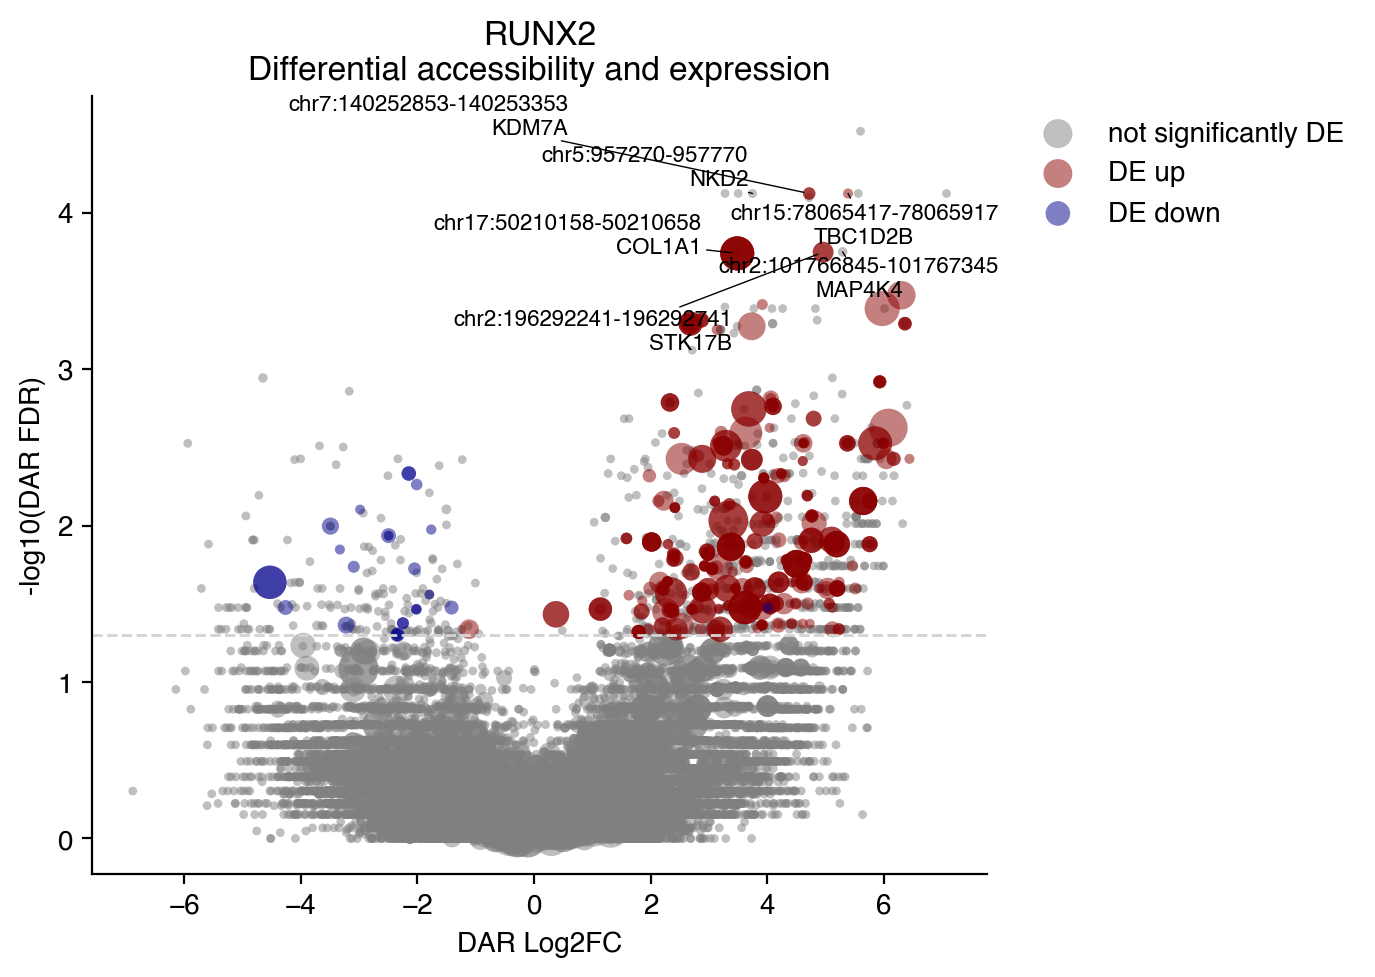

In [17]:
# Plot DAR volcano.
# Only significant DARs are coloured by DEG direction:
#   DAR significant + DEG up   = dark red
#   DAR significant + DEG down = dark blue
#   everything else            = grey
# Dot size increases with positive DEG logFC.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from adjustText import adjust_text

cell_types = ["RUNX2"]
top_n = 6

dar_fdr_cutoff = 0.05
deg_fdr_cutoff = 0.05

plot_df = dar_grn_deg[dar_grn_deg["Cell_type"].isin(cell_types)].copy()

plot_df["neg_log10_FDR"] = -np.log10(plot_df["FDR"].clip(lower=1e-300))
plot_df["neg_log10_deg_FDR"] = -np.log10(plot_df["deg_FDR"].clip(lower=1e-300))

plot_df["point_colour"] = "grey"

plot_df.loc[
    (plot_df["FDR"] < dar_fdr_cutoff) &
    (plot_df["deg_FDR"] < deg_fdr_cutoff) &
    (plot_df["deg_logFC"] > 0),
    "point_colour"
] = "darkred"

plot_df.loc[
    (plot_df["FDR"] < dar_fdr_cutoff) &
    (plot_df["deg_FDR"] < deg_fdr_cutoff) &
    (plot_df["deg_logFC"] < 0),
    "point_colour"
] = "darkblue"

plot_df["point_size"] = 10 + 2 * plot_df["neg_log10_deg_FDR"].clip(lower=0).fillna(0)

fig, ax = plt.subplots(figsize=(7, 5))

# Plot grey background first
for colour, label in [
    ("grey", "not significantly DE"),
    ("darkred", "DE up"),
    ("darkblue", "DE down")
]:
    subdf = plot_df[plot_df["point_colour"] == colour]

    ax.scatter(
        subdf["Log2FC"],
        subdf["neg_log10_FDR"],
        s=subdf["point_size"],
        c=colour,
        alpha=0.5,
        label=label,
        edgecolors="none"
    )

label_df = (
    plot_df
    .loc[plot_df["Gene"].notna()]
    .sort_values(
        ["neg_log10_FDR"],
        ascending=[False]
    )
    .drop_duplicates("peak")
    .head(top_n)
)

texts = []

for _, row in label_df.iterrows():

    label = f"{row['peak']}\n{row['Gene']}"

    texts.append(
        ax.text(
            row["Log2FC"],
            row["neg_log10_FDR"],
            label,
            fontsize=8
        )
    )

adjust_text(
    texts,
    ax=ax,
    arrowprops=dict(arrowstyle="-", lw=0.5)
)

ax.axhline(
    -np.log10(dar_fdr_cutoff),
    linestyle="--",
    color="lightgrey",
    linewidth=1
)

ax.set_xlabel("DAR Log2FC")
ax.set_ylabel("-log10(DAR FDR)")
ax.set_title("RUNX2\nDifferential accessibility and expression")

ax.legend(
    title="",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("RUNX2_DARs_DEGs_volcano.pdf")

plt.show()

In [ ]:
dar_grn_deg.to_csv('DAR_DEG_GRN.csv')

In [18]:
# COL1A1 entries in the original dataframe
dar_grn_deg.loc[
    dar_grn_deg['Gene'] == 'COL1A1'
].head(20)

,chr,start,end,Log2FC,FDR,MeanDiff,Cell_type,peak,Triplet,TF,...,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,deg_score,deg_logFC,deg_pval,deg_FDR
2225,chr17,50210871,50211371,-1.770843,0.896818,-0.032113,CEBPD,chr17:50210871-50211371,KLF6#chr17:50210871-50211371#COL1A1,KLF6,...,KLF6#COL1A1,16.0,16.0,16.0,16.0,16.0,-1.075486,-0.417673,0.282157,1.0
2226,chr17,50210871,50211371,-1.770843,0.896818,-0.032113,CEBPD,chr17:50210871-50211371,THRB#chr17:50210871-50211371#COL1A1,THRB,...,THRB#COL1A1,7.0,16.0,7.0,8.0,16.0,-1.075486,-0.417673,0.282157,1.0
10373,chr17,50150909,50151409,-0.861738,0.903088,-0.110203,CEBPD,chr17:50150909-50151409,KLF6#chr17:50150909-50151409#COL1A1,KLF6,...,KLF6#COL1A1,16.0,16.0,16.0,16.0,16.0,-1.075486,-0.417673,0.282157,1.0
10374,chr17,50151873,50152373,1.319031,0.903088,0.123738,CEBPD,chr17:50151873-50152373,KLF6#chr17:50151873-50152373#COL1A1,KLF6,...,KLF6#COL1A1,9.0,9.0,16.0,11.0,16.0,-1.075486,-0.417673,0.282157,1.0
10376,chr17,50210158,50210658,-0.553894,0.903088,-0.016899,CEBPD,chr17:50210158-50210658,BACH2#chr17:50210158-50210658#COL1A1,BACH2,...,BACH2#COL1A1,19.0,20.0,19.0,19.0,20.0,-1.075486,-0.417673,0.282157,1.0
10377,chr17,50210158,50210658,-0.553894,0.903088,-0.016899,CEBPD,chr17:50210158-50210658,FOSL1#chr17:50210158-50210658#COL1A1,FOSL1,...,FOSL1#COL1A1,11.0,20.0,11.0,11.0,18.0,-1.075486,-0.417673,0.282157,1.0
10379,chr17,50210158,50210658,-0.553894,0.903088,-0.016899,CEBPD,chr17:50210158-50210658,KLF6#chr17:50210158-50210658#COL1A1,KLF6,...,KLF6#COL1A1,16.0,20.0,16.0,16.0,16.0,-1.075486,-0.417673,0.282157,1.0
10380,chr17,50210158,50210658,-0.553894,0.903088,-0.016899,CEBPD,chr17:50210158-50210658,NFE2L2#chr17:50210158-50210658#COL1A1,NFE2L2,...,NFE2L2#COL1A1,9.0,20.0,9.0,11.0,20.0,-1.075486,-0.417673,0.282157,1.0
10381,chr17,50210158,50210658,-0.553894,0.903088,-0.016899,CEBPD,chr17:50210158-50210658,THRB#chr17:50210158-50210658#COL1A1,THRB,...,THRB#COL1A1,7.0,20.0,7.0,8.0,16.0,-1.075486,-0.417673,0.282157,1.0
74797,chr17,50117117,50117617,0.253657,0.991019,0.039689,CEBPD,chr17:50117117-50117617,FOXH1#chr17:50117117-50117617#COL1A1,FOXH1,...,FOXH1#COL1A1,5.0,15.0,5.0,5.0,11.0,-1.075486,-0.417673,0.282157,1.0
